# Objectif 

Recherche d'une situation passive favorable à la démonstration de la méthode de localisation dans le cas library actif / event passif.

Date de création : 28/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from datetime import datetime

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *

# Chargement des données 

## Données de la portion pour la librairie 
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [3]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath, auto_complex=True)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2323, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2671, mmsi: 526,
│   │                                    ais_datetime: 301, src_datetime: 937)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 21kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:0...
│   │         * src_datetime            (src_datetime) datetime64[ns] 7kB 2026-02-25T11:0...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 21kB ...
│   │           atl_lat                 (atl_datetime) float64 21kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 7kB ...
│   │           tir_vessel_lon          (src_datetime) float64 7kB ...
│   │           tir_vessel_lat          (src_datetime) float64 7kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 52kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 52kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 52kB ...
│   │       Attributes:
│   │           description:              Posi

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [4]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
print(ds_pos)

<xarray.Dataset> Size: 525MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 526,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 254MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_date

# Étude des positions des sources passives 

## Définition d'une zone d'intérêt

On commence par définir la zone de recherche. Cette zone correspond à la zone du maillage de la librairie + un petit offset pour mieux visualiser la trajectoire des sources avant et après avoir traversé la grille. 

In [5]:
# Step 1: select AIS pos in the area of interest
lon_offset_percentage = lat_offset_percentage = 0.00015

lon_min, lon_max = np.min([
    node.to_dataset().tir_src_lon.min() for _, node in portion.position.children.items()
]) * (1 - lon_offset_percentage / 2), np.max(
    [
    node.to_dataset().tir_src_lon.max() for _, node in portion.position.children.items()
]
) * (1 + lon_offset_percentage / 2)
lat_min, lat_max = np.min([
    node.to_dataset().tir_src_lat.min() for _, node in portion.position.children.items()
]) * (1 - lat_offset_percentage / 2), np.max(
    [
    node.to_dataset().tir_src_lat.max() for _, node in portion.position.children.items()
]
) * (1 + lat_offset_percentage / 2)
lon_min, lon_max, lat_min, lat_max

(np.float64(5.921525852249999),
 np.float64(5.962816177675),
 np.float64(42.986809747449996),
 np.float64(43.060361284900004))

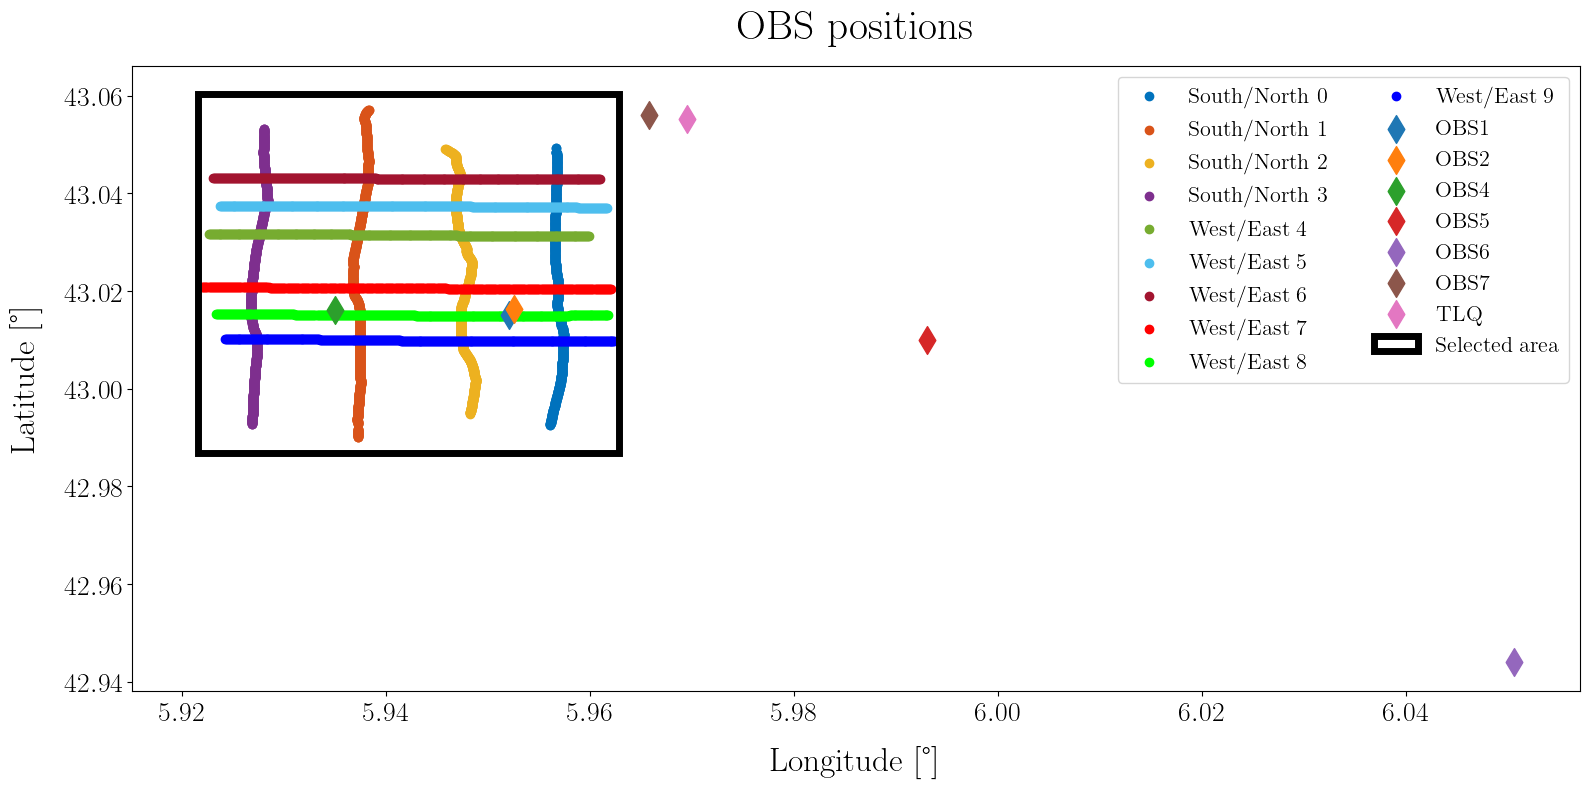

In [6]:
# Illustrate on map
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)
ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

## Position AIS 

On extrait ensuite les positions AIS qui passe dans la boite définie. 

In [7]:
ds_ais = ds_pos.copy().drop_vars(
    [v for v in list(ds_pos.variables) if v not in ["ais_lon", "ais_lat", "ais_datetime"]]
)

mask = (
    (ds_ais["ais_lon"] >= lon_min)
    & (ds_ais["ais_lon"] <= lon_max)
    & (ds_ais["ais_lat"] >= lat_min)
    & (ds_ais["ais_lat"] <= lat_max)
)

# Mask and drop coordinates that have no positions in the area
ds_ais_in_area = (
    ds_ais.where(mask).dropna("ais_datetime", how="all").dropna("mmsi", how="all")
)
# Add mmsi to ease selection
ds_ais_in_area = ds_ais_in_area.assign_coords(mmsi=np.arange(ds_ais_in_area.sizes["mmsi"]))
ds_ais_in_area

<xarray.Dataset> Size: 7MB
Dimensions:       (mmsi: 62, ais_datetime: 6638)
Coordinates:
  * mmsi          (mmsi) int64 496B 0 1 2 3 4 5 6 7 ... 54 55 56 57 58 59 60 61
  * ais_datetime  (ais_datetime) datetime64[ns] 53kB 2026-02-24T07:39:30 ... ...
Data variables:
    ais_lon       (mmsi, ais_datetime) float64 3MB nan nan nan ... nan nan nan
    ais_lat       (mmsi, ais_datetime) float64 3MB nan nan nan ... nan nan nan
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

# Filtrage des trajectoires : disponibilité et viabilité des données acoustiques 

On filtre les trajectoires AIS en rejettant les trajectoires qui présentent un des deux critères suivant : 

* Les données acoustiques ne sont pas disponible (passage en dehors de la période d'acquisition)
* La trajectoires coincide avec une période d'activité de la source acoustique (canon)

## Création du DataTree avec toutes les trajectoires candidates 

Certain navire (MMSI = 61 par exemple) traversent plusieurs fois la zone. Pour la localisation il est préferable de distinguer chaque trajectoire. 

In [8]:
# Cut into distinct events
event_sections = []
for m in ds_ais_in_area.mmsi.values:
    pos_mmsi = ds_ais_in_area.sel(mmsi=m)

    nan_indicator = np.isnan(pos_mmsi.ais_lon * pos_mmsi.ais_lat)
    edge_indicator = nan_indicator.astype(int)
    rising_edge = np.diff(edge_indicator.values, append=edge_indicator.values[-1]) == 1
    rising_edge_dt = pos_mmsi.ais_datetime.values[rising_edge]
    falling_edge = np.diff(edge_indicator.values, append=edge_indicator.values[-1]) == -1
    falling_edge_dt = pos_mmsi.ais_datetime.values[np.roll(falling_edge, +1)]       # Roll to avoid taking previosu point which is still a nan (diff = a[i+1] - a[i])

    n_section_for_current_mmsi = max(rising_edge_dt.size, falling_edge_dt.size)

    if n_section_for_current_mmsi == 0:
        continue 
    
    # Edges might not be visible
    if falling_edge_dt.size < n_section_for_current_mmsi:
        falling_edge_dt = np.concat([[pos_mmsi.ais_datetime.values[0]], falling_edge_dt])
    if rising_edge_dt.size < n_section_for_current_mmsi:
        rising_edge_dt = np.concat([rising_edge_dt, [pos_mmsi.ais_datetime.values[-1]]])

    for isec in range(n_section_for_current_mmsi):
        pos_sec = pos_mmsi.sel(
            ais_datetime=slice(falling_edge_dt[isec], rising_edge_dt[isec])
        )
        event_sections.append(pos_sec)

In [9]:
portion_event = xr.DataTree()
event_ids = np.arange(len(event_sections))
portion_event["event_id"] = event_ids
portion_event.attrs = dict(
    box_lon_min=lon_min, box_lon_max=lon_max, box_lat_min=lat_min, box_lat_max=lat_max
)

for isec, pos_sec in enumerate(event_sections):

    ds_event_i = pos_sec.rename(
        dict(ais_datetime="datetime", ais_lon="lon", ais_lat="lat")
    )
    ds_event_i = ds_event_i.drop_vars("mmsi")
    ds_event_i["start_datetime"] = ds_event_i.datetime.min().values
    ds_event_i["stop_datetime"] = ds_event_i.datetime.max().values
    ds_event_i.attrs["event_id"] = isec
    ds_event_i.attrs["MMSI"] = pos_sec.mmsi.values

    path = f"position/event_{isec}"
    portion_event[path] = ds_event_i

In [10]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 85)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 680B 0 1 2 3 4 5 6 7 8 ... 77 78 79 80 81 82 83 84
│   Attributes:
│       box_lon_min:  5.921525852249999
│       box_lon_max:  5.962816177675
│       box_lat_min:  42.986809747449996
│       box_lat_max:  43.060361284900004
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 85)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 680B 2026-02-24T07:42:20 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 680B 5.951 5.951 5.95 ... 5.922 5.922
    │           lat             (datetime) float64 680B 43.06 43.06 43.06 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-24T07:42:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T07:56:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     0
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 12)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 96B 2026-02-27T09:04:30 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 96B 5.922 5.922 5.923 ... 5.929 5.93
    │           lat             (datetime) float64 96B 43.06 43.06 43.06 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-27T09:04:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:06:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     1
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 33)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 264B 2026-02-24T12:46:30 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 264B 5.922 5.923 5.924 ... 5.961 5.962
    │           lat             (datetime) float64 264B 43.03 43.03 43.03 ... 43.03 43.03
    │           start_datetime  datetime64[ns] 8B 2026-02-24T12:46:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T12:51:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     2
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 85)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 680B 2026-02-24T14:42:00 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 680B 5.962 5.962 5.962 ... 5.961 5.962
    │           lat             (datetime) float64 680B 43.05 43.04 43.04 ... 43.01 43.01
    │           start_datetime  datetime64[ns] 8B 2026-02-24T14:42:00
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T14:56:00
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     3
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 5)
    │       Coordinates:
    │         

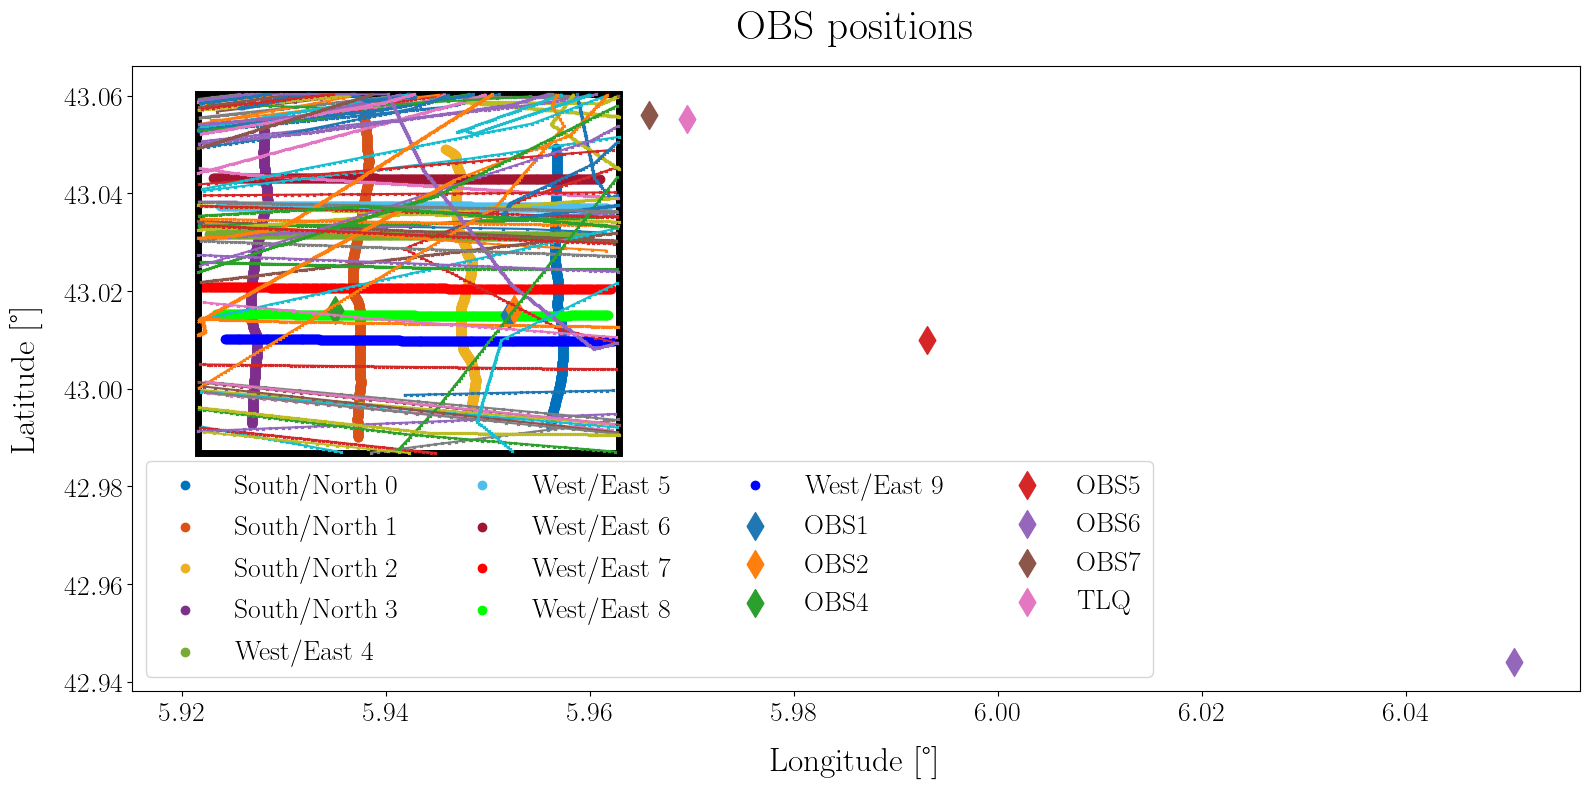

In [11]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event.box_lon_min, portion_event.box_lat_min),
        portion_event.box_lon_max - portion_event.box_lon_min,
        portion_event.box_lat_max - portion_event.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

# ax.legend()
# legend = ax.get_legend()

# if legend is not None:
#     handles = legend.legend_handles
#     labels = [text.get_text() for text in legend.get_texts()]

#     legend.remove()

#     ax.legend(
#         handles,
#         labels,
#         loc="upper right",
#         fontsize=16,
#         ncols=2,
#     )

## Chargement des signaux 

In [12]:
ds_pressure = xr.open_dataset(ACOUPLANE_PRESSURE_NC_FPATH)
ds_pressure

<xarray.Dataset> Size: 22GB
Dimensions:         (time_obs1: 996000000, time_obs2: 1000246750,
                     time_obs4: 993600000, time_obs5: 831600000,
                     time_obs6: 819000000, time_obs7: 850177000, obs_id: 6)
Coordinates:
  * obs_id          (obs_id) <U4 96B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
Dimensions without coordinates: time_obs1, time_obs2, time_obs4, time_obs5,
                                time_obs6, time_obs7
Data variables:
    pressure_obs1   (time_obs1) int32 4GB ...
    pressure_obs2   (time_obs2) int32 4GB ...
    pressure_obs4   (time_obs4) int32 4GB ...
    pressure_obs5   (time_obs5) int32 3GB ...
    pressure_obs6   (time_obs6) int32 3GB ...
    pressure_obs7   (time_obs7) int32 3GB ...
    start_datetime  (obs_id) datetime64[ns] 48B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

## Premier tri : disponibilité des données OBS 

Dans un premier temps on sélectionne les évenement AIS pour lesquels on dispose des données OBS. 

In [13]:
for o_id in ds_pressure.obs_id.values:
    start = ds_pressure.start_datetime.sel(obs_id=o_id).values
    stop = start + np.timedelta64(
        int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{o_id}"] * 1e6), "us"
    )
    print(f"{o_id.upper()}:  start = {start}, stop = {stop}")

OBS1:  start = 2026-02-24T13:40:00.000000000, stop = 2026-03-02T08:00:00.000000000
OBS2:  start = 2026-02-24T12:45:00.000000000, stop = 2026-03-02T07:40:23.375000000
OBS4:  start = 2026-02-24T13:00:00.000000000, stop = 2026-03-02T07:00:00.000000000
OBS5:  start = 2026-02-24T16:00:00.000000000, stop = 2026-03-01T11:30:00.000000000
OBS6:  start = 2026-02-24T16:30:00.000000000, stop = 2026-03-01T10:15:00.000000000
OBS7:  start = 2026-02-24T09:30:00.000000000, stop = 2026-03-01T07:34:48.500000000


Text(0.5, 1.0, 'Event AIS et émissions')

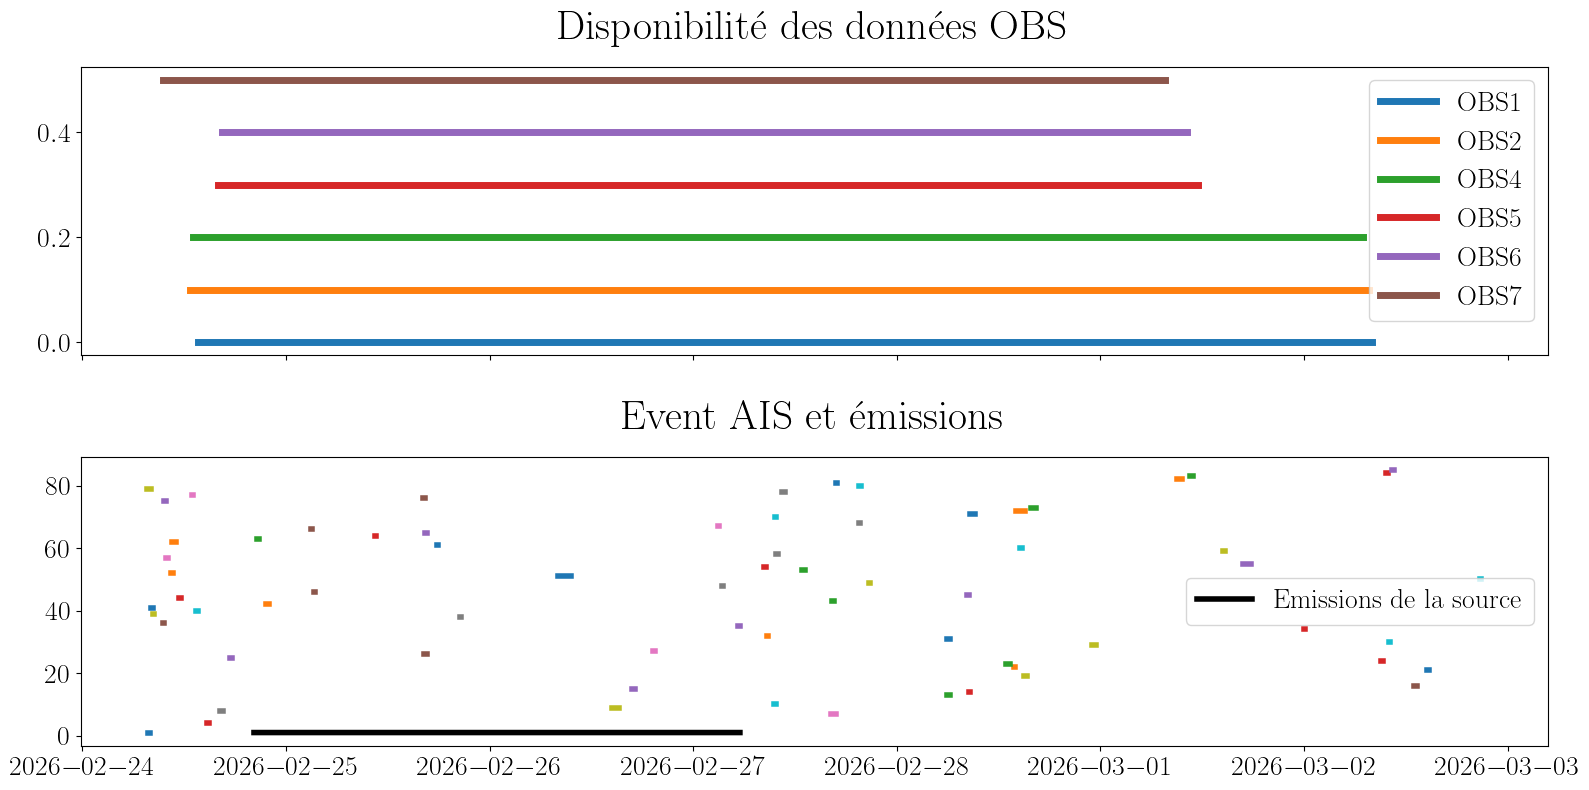

In [14]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

for iobs, o_id in enumerate(ds_pressure.obs_id.values):
    start = ds_pressure.start_datetime.sel(obs_id=o_id).values
    stop = start + np.timedelta64(
        int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{o_id}"] * 1e6), "us"
    )

    axs[0].plot([start, stop], [iobs / 10, iobs / 10], label=f"{o_id.upper()}", linewidth=5)
axs[0].legend()
axs[0].set_title("Disponibilité des données OBS")

axs[1].plot(
    ds_pos.src_datetime,
    np.ones(ds_pos.src_datetime.size),
    color="k",
    label="Emissions de la source",
    linewidth=4,
)
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()
    axs[1].plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id,
        linewidth=4,
    )

axs[1].legend()
axs[1].set_title("Event AIS et émissions")

**Note** Au 18/11/2026 deux fichiers de l'OBS 2 sont toujours manquant. Ici, on ne tient pas compte de ces trous dans les données et certaines des trajectoires sont susceptibles de ne pas avoir de données pour l'OBS 2. 

In [15]:
event_to_drop = []
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    invalid_event = False
    for obs_id in ds_pressure.obs_id.values:

        start = ds_pressure.start_datetime.sel(obs_id=obs_id).values
        stop = start + np.timedelta64(
            int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{obs_id}"] * 1e6), "us"
        )

        # Check if any data is available
        event_stops_before_recording = start >= event_stop
        event_starts_after_recording = stop <= event_start

        # event_stops_before_recording = obs_datetimes[obs_id][0] >= event_stop
        # event_starts_after_recording = obs_datetimes[obs_id][-1] <= event_start
        no_data = event_stops_before_recording or event_starts_after_recording
        if no_data:
            # print(f"OBS '{obs_id}' has no data between {event_start} and {event_stop} (recording spans {start} -> {stop}).")
            invalid_event = True

    if invalid_event:
        # portion_event.drop_nodes()
        # print(f"Event {name} dropped")
        event_to_drop.append(name)

In [16]:
n_unvalid_event = len(event_to_drop)
print(f"{n_unvalid_event}/{portion_event.event_id.size} events dropped (no data available)")

30/85 events dropped (no data available)


In [17]:
valid_events = []
for name, node in portion_event.position.children.items():
    
    if name in event_to_drop:   # Dropped according to first condition : no data available 
        continue 
    valid_events.append(name)

len(valid_events)

55

In [18]:
# Rebuild datatree with correct event names once unvalid ones have been dropped
portion_event_filter = xr.DataTree()

for e_id_new, event_name in enumerate(valid_events):
    
    path_pos = f"position/{event_name}"
    new_path_pos = f"position/event_{e_id_new}"
    old_pos_event = portion_event[path_pos].to_dataset()
    old_pos_event.attrs["event_id"] = e_id_new
    portion_event_filter[new_path_pos] = old_pos_event

    # path_press = f"pressure/{event_name}"
    # new_path_press = f"pressure/event_{e_id_new}"
    # old_press_event = portion_event[path_press].to_dataset()
    # old_press_event.attrs["event_id"] = e_id_new
    # portion_event_filter[new_path_press] = old_press_event

portion_event_filter["event_id"] = np.arange(len(valid_events))
portion_event_filter.attrs = portion_event.attrs

del portion_event
portion_event = portion_event_filter.copy()
del portion_event_filter

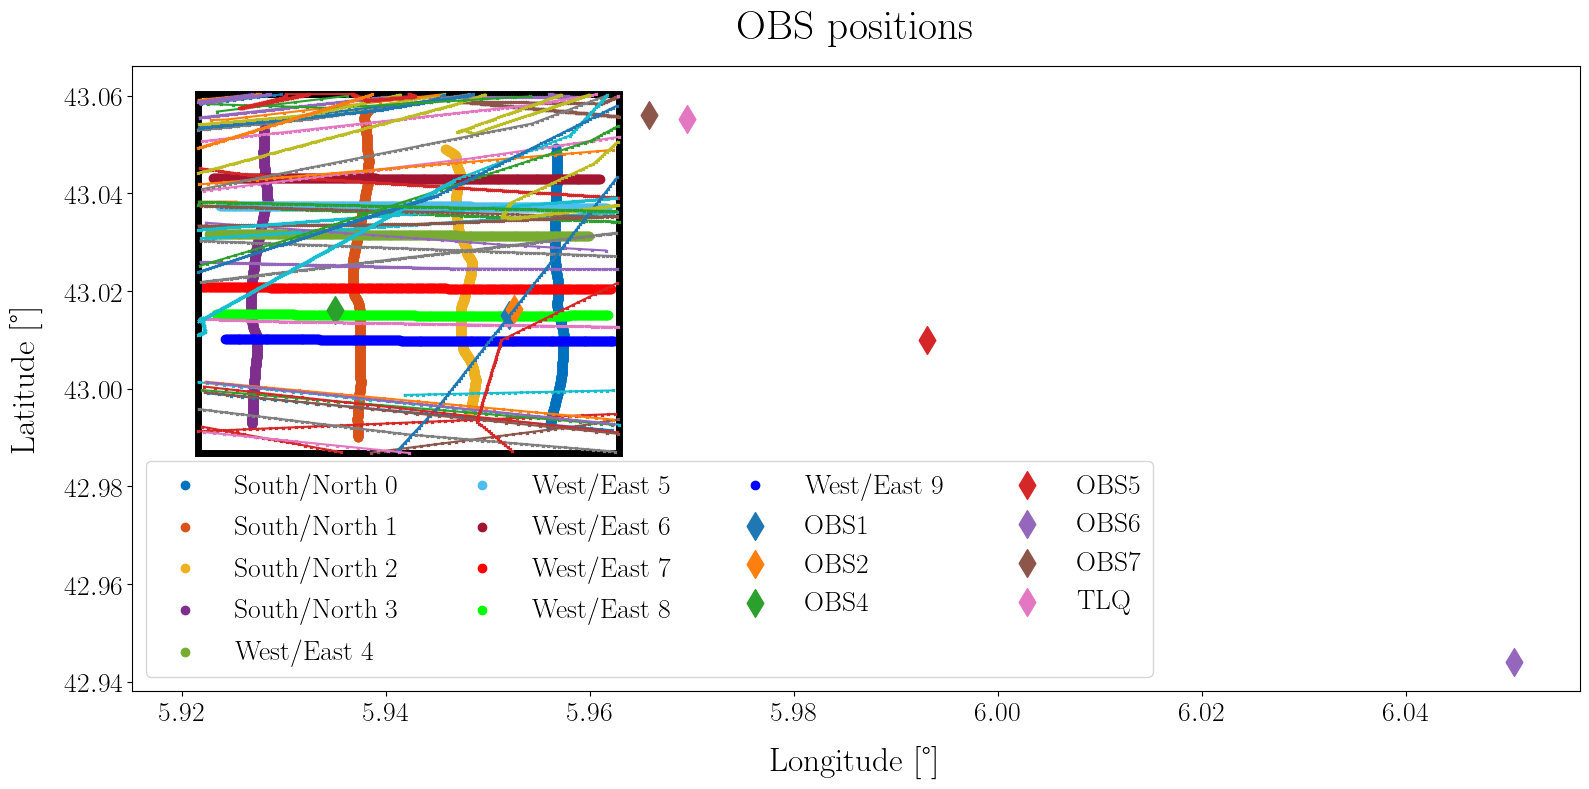

In [19]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event.box_lon_min, portion_event.box_lat_min),
        portion_event.box_lon_max - portion_event.box_lon_min,
        portion_event.box_lat_max - portion_event.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

# ax.legend(ncols=3)

Text(0.5, 1.0, 'Event AIS et émissions')

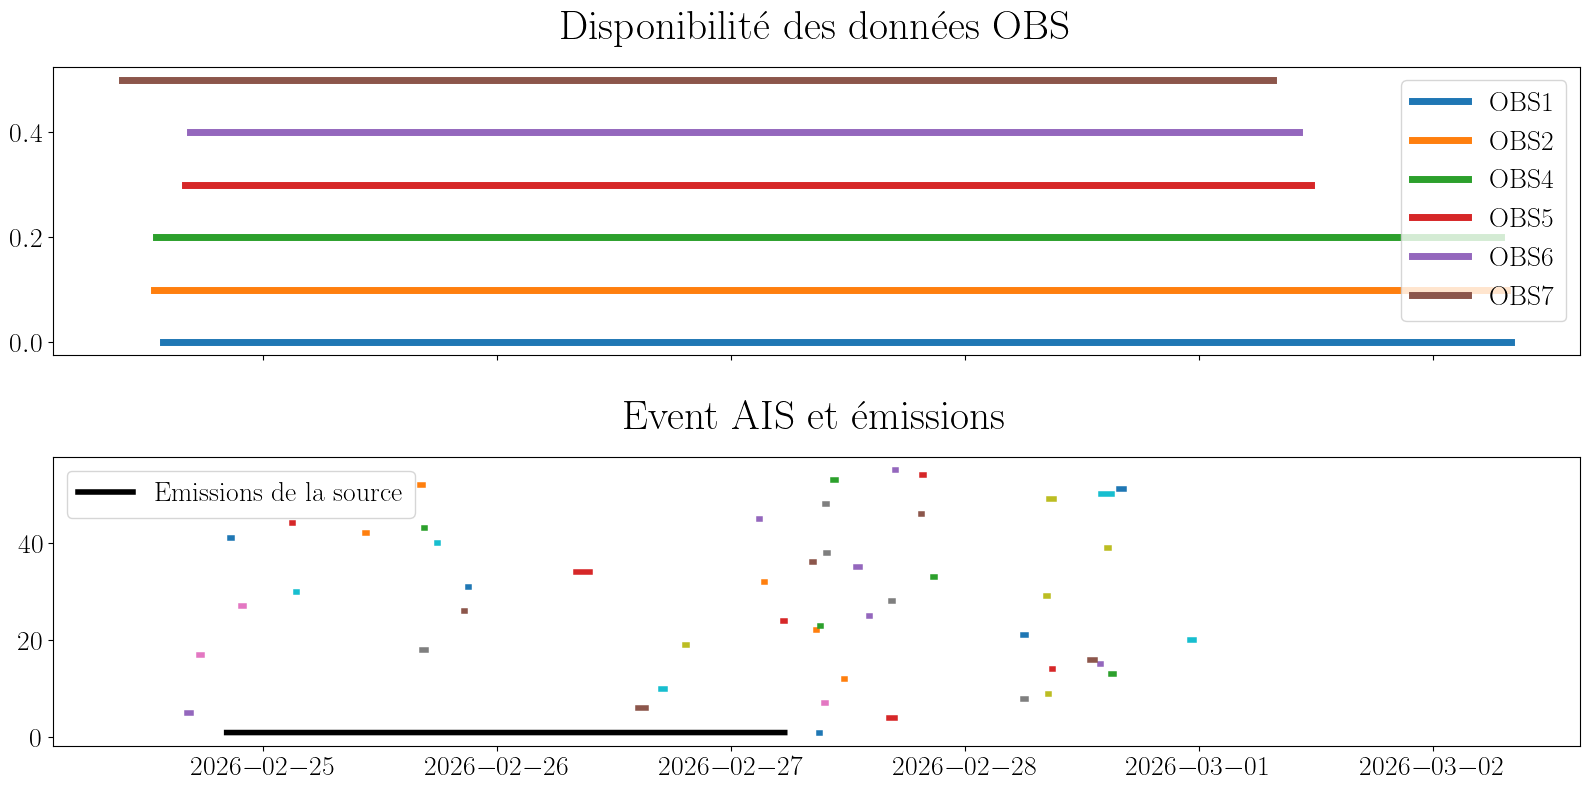

In [20]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

for iobs, o_id in enumerate(ds_pressure.obs_id.values):
    start = ds_pressure.start_datetime.sel(obs_id=o_id).values
    stop = start + np.timedelta64(
        int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{o_id}"] * 1e6), "us"
    )

    axs[0].plot([start, stop], [iobs / 10, iobs / 10], label=f"{o_id.upper()}", linewidth=5)
axs[0].legend()
axs[0].set_title("Disponibilité des données OBS")

axs[1].plot(
    ds_pos.src_datetime,
    np.ones(ds_pos.src_datetime.size),
    color="k",
    label="Emissions de la source",
    linewidth=4,
)
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()
    axs[1].plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id,
        linewidth=4,
    )

axs[1].legend()
axs[1].set_title("Event AIS et émissions")

## Deuxième tri : donnée hors de la période des tirs 

On cherche ensuite des données hors de la période des émissions.

In [21]:
valid_events = []
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    # First option : filter to avoid any emission
    event_stops_before_first_emission = ds_pos.src_datetime.values[0] >= event_stop
    event_starts_after_last_emission = ds_pos.src_datetime.values[-1] <= event_start
    valid_event = event_stops_before_first_emission or event_starts_after_last_emission

    if valid_event:
        valid_events.append(name)
print(f"Nombre de séquences valides : {len(valid_events)}")

Nombre de séquences valides : 33


In [22]:
# Rebuild datatree with correct event names once unvalid ones have been dropped
portion_event_filter = xr.DataTree()

for e_id_new, event_name in enumerate(valid_events):
    
    path_pos = f"position/{event_name}"
    new_path_pos = f"position/event_{e_id_new}"
    old_pos_event = portion_event[path_pos].to_dataset()
    old_pos_event.attrs["event_id"] = e_id_new
    portion_event_filter[new_path_pos] = old_pos_event

portion_event_filter["event_id"] = np.arange(len(valid_events))
portion_event_filter.attrs = portion_event.attrs

# NOTE : pas d'update -> étape deux avec filtrage des émissions OBS 6
# del portion_event
# portion_event = portion_event_filter.copy()
# del portion_event_filter

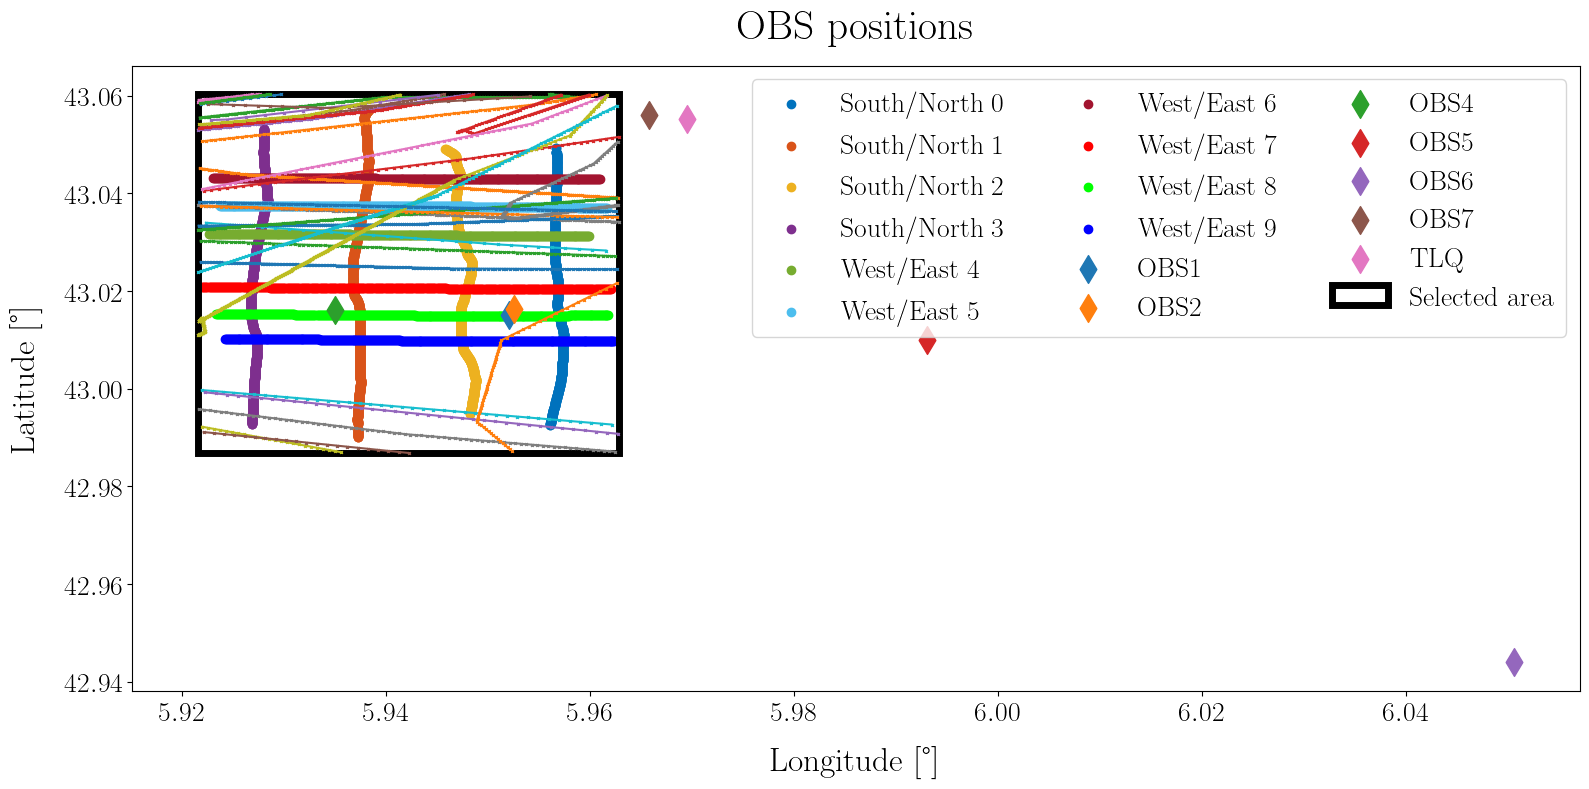

In [23]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event_filter.box_lon_min, portion_event_filter.box_lat_min),
        portion_event_filter.box_lon_max - portion_event_filter.box_lon_min,
        portion_event_filter.box_lat_max - portion_event_filter.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)
ax.legend(ncols=3)

for name, node in portion_event_filter.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon,
        ds_position_section.lat,
        "-x",
        markersize=2,
        label=f"Event {ds_position_section.event_id}",
    )

# ax.legend()
# legend = ax.get_legend()

# if legend is not None:
#     handles = legend.legend_handles
#     labels = [text.get_text() for text in legend.get_texts()]

#     legend.remove()

#     ax.legend(
#         handles,
#         labels,
#         loc="upper right",
#         fontsize=16,
#         ncols=2,
#     )

In [24]:
# event_to_drop = []
# for name, node in portion_event_filter.position.children.items():
#     ds_position_event = node.to_dataset()

#     event_start = ds_position_event.start_datetime.values
#     event_stop = ds_position_event.stop_datetime.values

#     # NOTE : this section should be useless considering previous filters it is just a extra level of security
#     invalid_event = False
#     for obs_id in ds_pressure.obs_id.values:
#         # Check if any data is available
#         start = ds_pressure.start_datetime.sel(obs_id=obs_id).values
#         stop = start + np.timedelta64(
#             int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{obs_id}"] * 1e6), "us"
#         )
#         event_stops_before_recording = start >= event_stop
#         event_starts_after_recording = stop <= event_start
#         no_data = event_stops_before_recording or event_starts_after_recording
#         if no_data:
#             print(f"OBS '{obs_id}' has no data between {event_start} and {event_stop} (recording spans {start} -> {stop}).")
#             invalid_event = True

#     if invalid_event:
#         # portion_event.drop_nodes()
#         print(f"Event {name} dropped")
#         event_to_drop.append(name)
#         continue

#     ds_pressure_event = extract_pressure_section(
#         event_start,
#         event_stop,
#         ds_pressure,
#         obs_datetimes=None,
#     )
#     ds_pressure_event = convert_raw_pressure_to_physical_units(
#         ds_pressure=ds_pressure_event
#     )

#     ds_pressure_event.attrs["event_id"] = ds_position_event.event_id

#     # Store in event portion
#     path = f"pressure/event_{ds_position_event.event_id}"
#     portion_event_filter[path] = ds_pressure_event

In [25]:
# # Plot
# single_fig = False
# for name, node in portion_event_filter.pressure.children.items():
#     ds_pressure_section = node.to_dataset()
#     fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
#     fig.suptitle(f"Event {ds_pressure_section.event_id}")
#     plt.show()

In [26]:
# # Plot
# for name, node in portion_event_filter.pressure.children.items():
#     ds_pressure_section = node.to_dataset()
#     try:
#         fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
#     except:
#         print(f"Data with different length event : {name}")
#     fig.suptitle(f"Event {ds_pressure_section.event_id}")
#     plt.show()

In [27]:
# portion_event_filter

In [28]:
# portion_ef = portion_event_filter.match("*event_2")
# # Save as netcdf
# fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
# portion_ef.attrs["portion_filepath"] = fpath
# portion_ef.to_netcdf(fpath)

## Deuxième tri : donnée hors de la période des tirs (approche moins restrictive en conservant les périodes d'émissions loin du réseau) 

Afin de conserver d'avantage de trajectoire AIS on peut relaxer le critère de séléction. Pour ce faire, on conserve les trajectoires AIS correspondant aux périodes d'émissions proche de l'OBS 6. En effet, ces émissions sont éloignées du réseau de capteurs considéré et doivent donc vraisemblablement être reçues avec un faible SNR. On peut donc supposer que la composante signal des détonations est négligeable devant le bruit des navires circulant dans le réseau.  

### Filtrage des émissions au dessus de l'OBS 6

La période d'émission proche OBS 6 est déterminée visuellement sur la base des positions de la source en ajustant les bornes temporelles.  

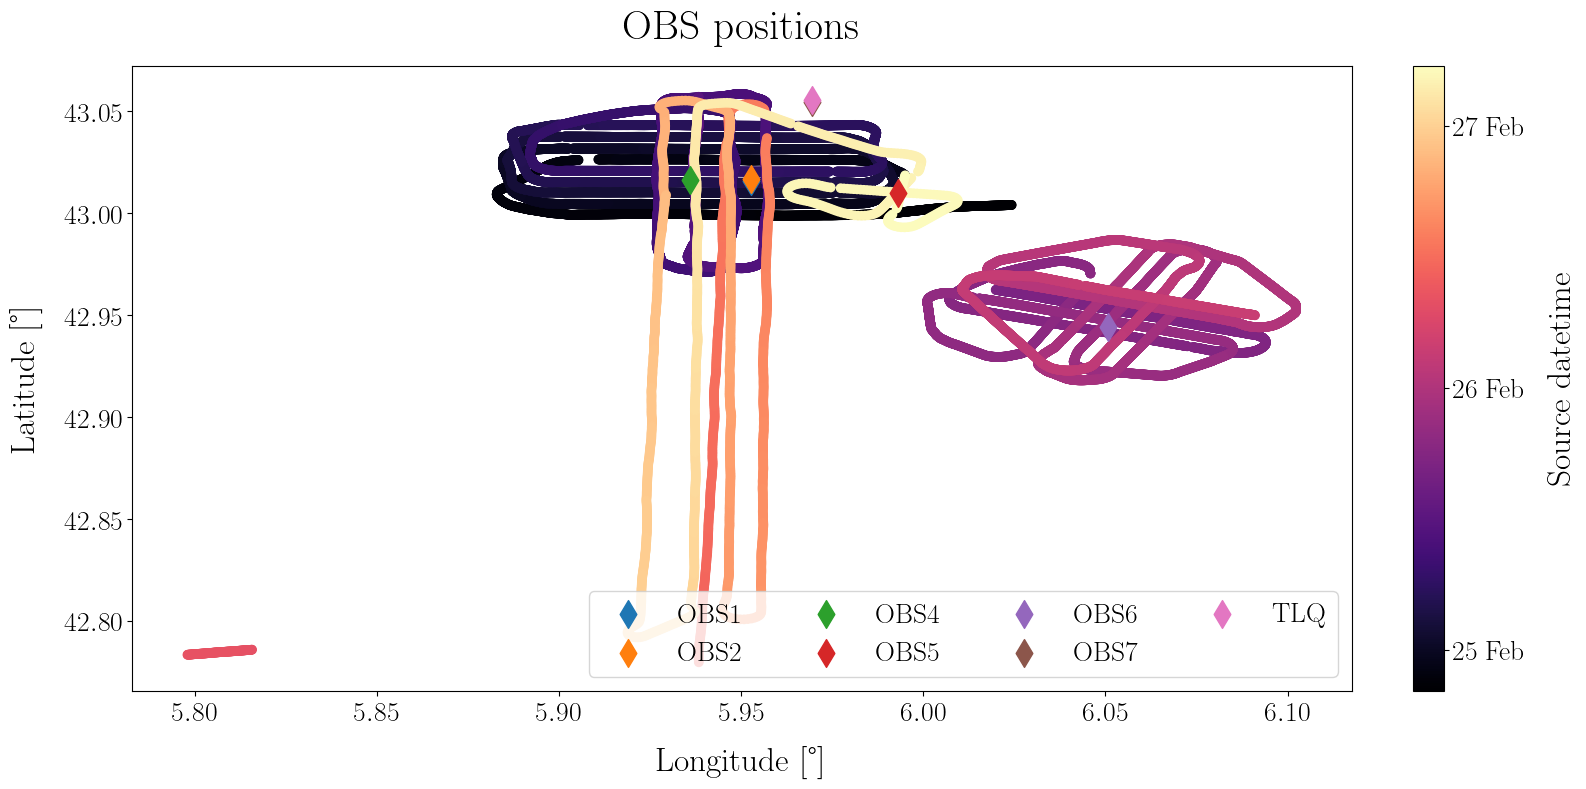

In [29]:
fig, ax = plt.subplots()

dates = ds_pos.src_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos.tir_src_lon,
    ds_pos.tir_src_lat,
    c=date_num,
    cmap="magma",
)

plot_obs_pos(ds_pos, ax=ax)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Source datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

In [30]:
filter1_stop = datetime(2026, 2, 25, 16, 40, 0)
ds_pos_filtered = ds_pos.copy()
ds_pos_filtered1 = ds_pos_filtered.sel(src_datetime=slice(ds_pos_filtered.src_datetime.values[0], filter1_stop))

filter2_start = datetime(2026, 2, 26, 4, 0, 0)
ds_pos_filtered2 = ds_pos_filtered.sel(src_datetime=slice(filter2_start, ds_pos_filtered.src_datetime.values[-1]))

ds_pos_filtered1.src_datetime, ds_pos_filtered2.src_datetime

(<xarray.DataArray 'src_datetime' (src_datetime: 18528)> Size: 148kB
 array(['2026-02-24T20:14:06.600098000', '2026-02-24T20:14:09.600098000',
        '2026-02-24T20:14:12.600098000', ..., '2026-02-25T11:52:18.600098000',
        '2026-02-25T11:52:21.600098000', '2026-02-25T11:52:24.600098000'],
       shape=(18528,), dtype='datetime64[ns]')
 Coordinates:
   * src_datetime  (src_datetime) datetime64[ns] 148kB 2026-02-24T20:14:06.600...,
 <xarray.DataArray 'src_datetime' (src_datetime: 2289)> Size: 18kB
 array(['2026-02-26T07:59:48.800049000', '2026-02-26T07:59:51.800049000',
        '2026-02-26T07:59:54.800049000', ..., '2026-02-27T05:29:30.200073000',
        '2026-02-27T05:30:00.200073000', '2026-02-27T05:30:30.200073000'],
       shape=(2289,), dtype='datetime64[ns]')
 Coordinates:
   * src_datetime  (src_datetime) datetime64[ns] 18kB 2026-02-26T07:59:48.8000...)

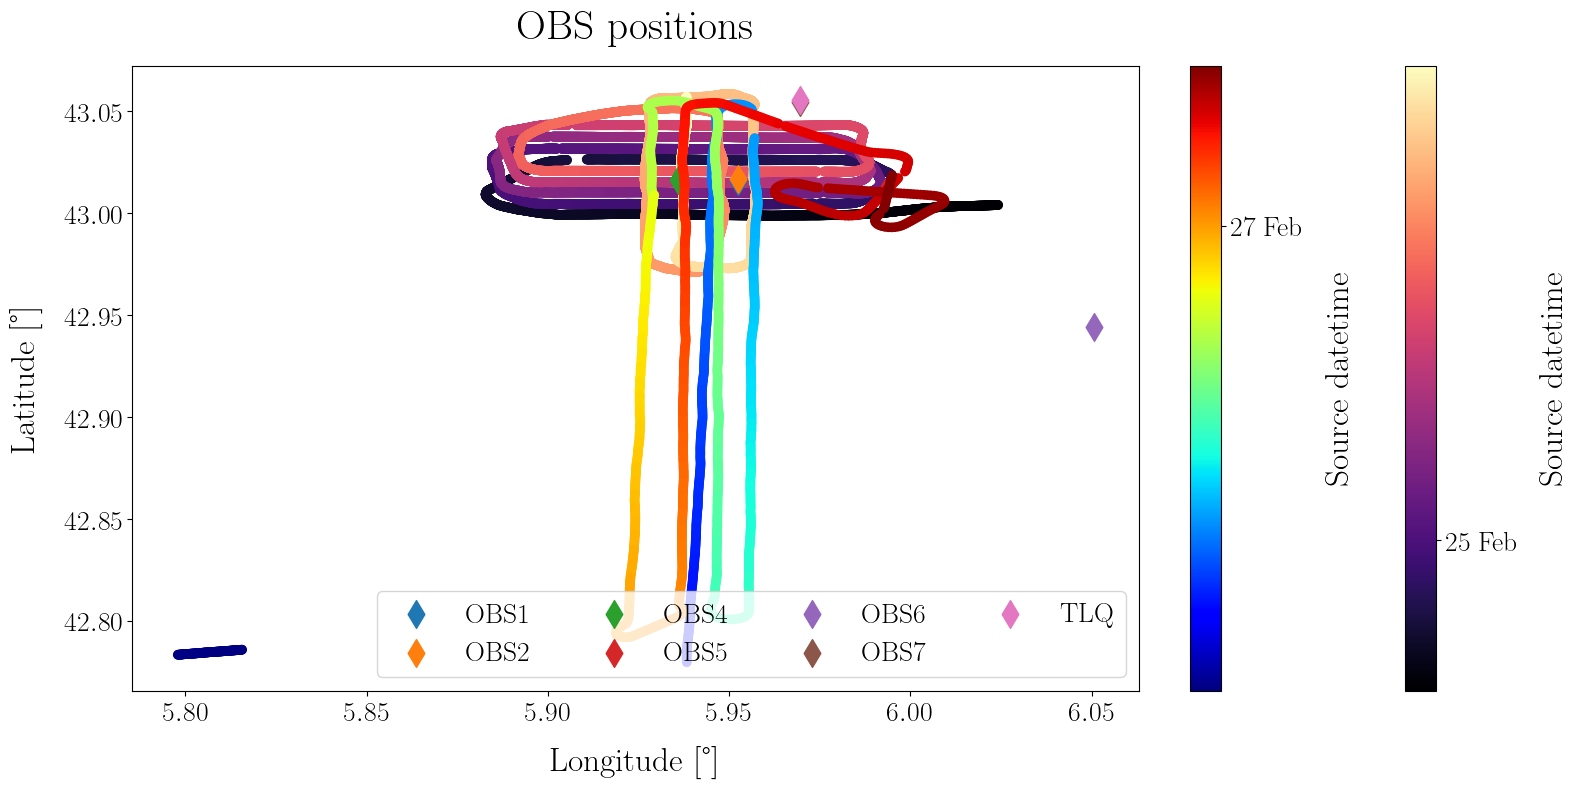

In [31]:
fig, ax = plt.subplots()

dates = ds_pos_filtered1.src_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_filtered1.tir_src_lon,
    ds_pos_filtered1.tir_src_lat,
    c=date_num,
    cmap="magma",
)

plot_obs_pos(ds_pos_filtered1, ax=ax)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Source datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

dates = ds_pos_filtered2.src_datetime.values
date_num = mdates.date2num(dates)

sc = ax.scatter(
    ds_pos_filtered2.tir_src_lon,
    ds_pos_filtered2.tir_src_lat,
    c=date_num,
    cmap="jet",
)


cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Source datetime")
cbar.ax.yaxis.set_major_locator(mdates.DayLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


Text(0.5, 1.0, 'Event AIS et émissions')

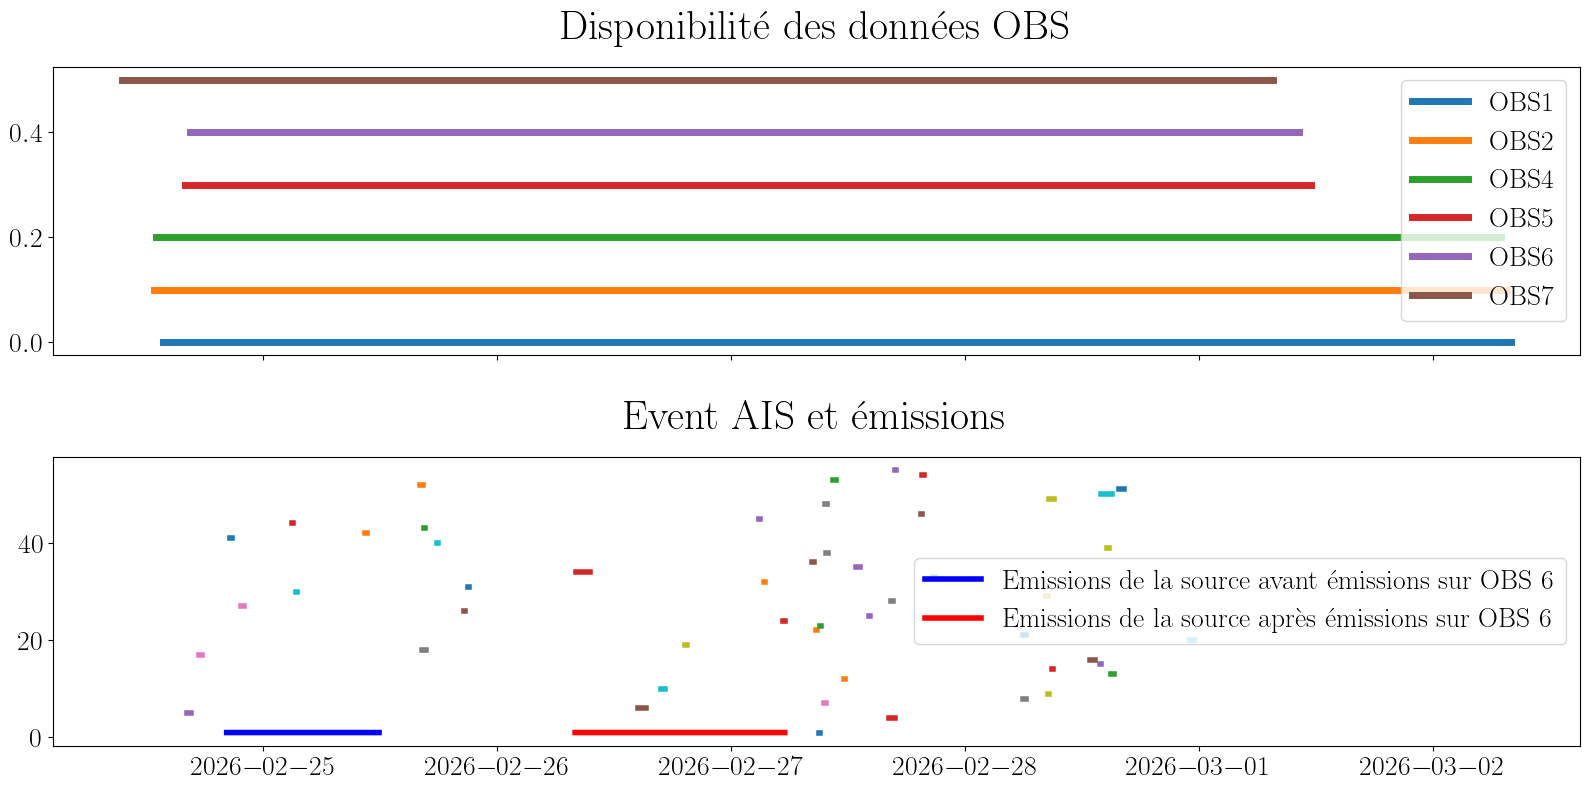

In [32]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

for iobs, o_id in enumerate(ds_pressure.obs_id.values):
    start = ds_pressure.start_datetime.sel(obs_id=o_id).values
    stop = start + np.timedelta64(
        int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{o_id}"] * 1e6), "us"
    )

    axs[0].plot([start, stop], [iobs / 10, iobs / 10], label=f"{o_id.upper()}", linewidth=5)
axs[0].legend()
axs[0].set_title("Disponibilité des données OBS")

axs[1].plot(
    ds_pos_filtered1.src_datetime,
    np.ones(ds_pos_filtered1.src_datetime.size),
    color="b",
    label="Emissions de la source avant émissions sur OBS 6",
    linewidth=4,
)

axs[1].plot(
    ds_pos_filtered2.src_datetime,
    np.ones(ds_pos_filtered2.src_datetime.size),
    color="r",
    label="Emissions de la source après émissions sur OBS 6",
    linewidth=4,
)

for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    # if ds_position_event.event_id  == 10:
    #     print(ds_position_event.datetime)
    axs[1].plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id ,
        linewidth=4,
    )

axs[1].legend()
axs[1].set_title("Event AIS et émissions")

# dt0 = datetime(2026, 2, 24, 20, 15)
# dt1 = datetime(2026, 2, 24, 21, 15)
# plt.xlim(dt0, dt1)

Une fois la portion émise au dessus de l'OBS 6 retirée on peut filtrer. 

In [33]:
valid_events = []

for name, node in portion_event.position.children.items():
    
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    # First option : filter to avoid any emission 
    # event_stops_before_first_emission = ds_pos_filtered.src_datetime.values[0] >= event_stop
    # event_starts_after_last_emission = ds_pos_filtered.src_datetime.values[-1] <= event_start
    # valid_event = event_stops_before_first_emission or event_starts_after_last_emission

    # Second option keep event if emission are emitted clsoe to OBS 6 
    event_stops_before_first_emission1 = ds_pos_filtered1.src_datetime.values[0] >= event_stop
    event_starts_after_last_emission1 = ds_pos_filtered1.src_datetime.values[-1] <= event_start
    valid_event1 = event_stops_before_first_emission1 or event_starts_after_last_emission1

    event_stops_before_first_emission2 = ds_pos_filtered2.src_datetime.values[0] >= event_stop
    event_starts_after_last_emission2 = ds_pos_filtered2.src_datetime.values[-1] <= event_start
    valid_event2 = event_stops_before_first_emission2 or event_starts_after_last_emission2

    valid_event = valid_event1 and valid_event2
    if valid_event:
        valid_events.append(name)

# else:
# # valid_events = [name for name in list(portion_event.position.children) if name not in event_to_drop]
# valid_events = ["event_83"]

Avec la seconde option on conserve davantage d'évenements. 

In [34]:
# Rebuild datatree with correct event names once unvalid ones have been dropped
portion_event_filter = xr.DataTree()

for e_id_new, event_name in enumerate(valid_events):
    
    path_pos = f"position/{event_name}"
    new_path_pos = f"position/event_{e_id_new}"
    old_pos_event = portion_event[path_pos].to_dataset()
    old_pos_event.attrs["event_id"] = e_id_new
    portion_event_filter[new_path_pos] = old_pos_event

    # path_press = f"pressure/{event_name}"
    # new_path_press = f"pressure/event_{e_id_new}"
    # old_press_event = portion_event[path_press].to_dataset()
    # old_press_event.attrs["event_id"] = e_id_new
    # portion_event_filter[new_path_press] = old_press_event

portion_event_filter["event_id"] = np.arange(len(valid_events))
portion_event_filter.attrs = portion_event.attrs

del portion_event
portion_event = portion_event_filter.copy()
del portion_event_filter

In [35]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 39)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 312B 0 1 2 3 4 5 6 7 8 ... 31 32 33 34 35 36 37 38
│   Attributes:
│       box_lon_min:  5.921525852249999
│       box_lon_max:  5.962816177675
│       box_lat_min:  42.986809747449996
│       box_lat_max:  43.060361284900004
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 12)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 96B 2026-02-27T09:04:30 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 96B 5.922 5.922 5.923 ... 5.929 5.93
    │           lat             (datetime) float64 96B 43.06 43.06 43.06 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-27T09:04:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:06:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     1
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 204)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-27T16:13:30 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 2kB 5.963 5.963 5.962 ... 5.922 5.922
    │           lat             (datetime) float64 2kB 43.04 43.04 43.04 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-27T16:13:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T16:47:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     6
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 148)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T16:10:40 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 5.956 5.956 5.956 ... 5.922 5.922
    │           lat             (datetime) float64 1kB 43.06 43.06 43.06 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-24T16:10:40
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T16:35:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     7
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 58)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 464B 2026-02-27T09:33:20 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 464B 5.922 5.923 5.924 ... 5.962 5.963
    │           lat             (datetime) float64 464B 43.04 43.04 43.04 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-27T09:33:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:42:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     9
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 99)
    │       Coordinates:
    │         

Text(0.5, 1.0, 'Event AIS et émissions')

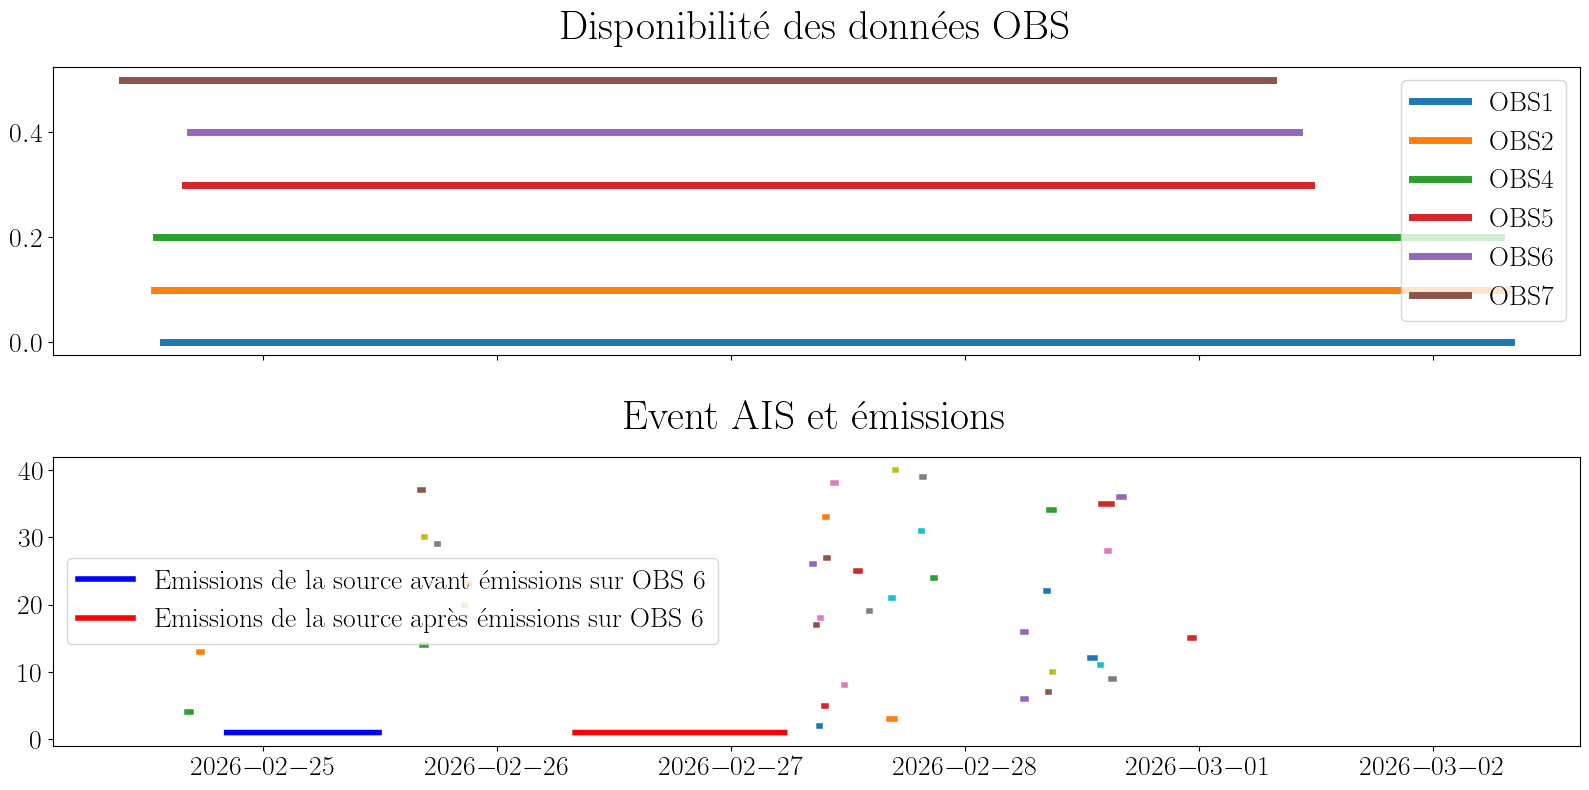

In [36]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

for iobs, o_id in enumerate(ds_pressure.obs_id.values):
    start = ds_pressure.start_datetime.sel(obs_id=o_id).values
    stop = start + np.timedelta64(
        int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{o_id}"] * 1e6), "us"
    )

    axs[0].plot([start, stop], [iobs / 10, iobs / 10], label=f"{o_id.upper()}", linewidth=5)
axs[0].legend()
axs[0].set_title("Disponibilité des données OBS")

axs[1].plot(
    ds_pos_filtered1.src_datetime,
    np.ones(ds_pos_filtered1.src_datetime.size),
    color="b",
    label="Emissions de la source avant émissions sur OBS 6",
    linewidth=4,
)

axs[1].plot(
    ds_pos_filtered2.src_datetime,
    np.ones(ds_pos_filtered2.src_datetime.size),
    color="r",
    label="Emissions de la source après émissions sur OBS 6",
    linewidth=4,
)

for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()
    axs[1].plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id + 1 ,
        linewidth=4,
    )

axs[1].legend()
axs[1].set_title("Event AIS et émissions")

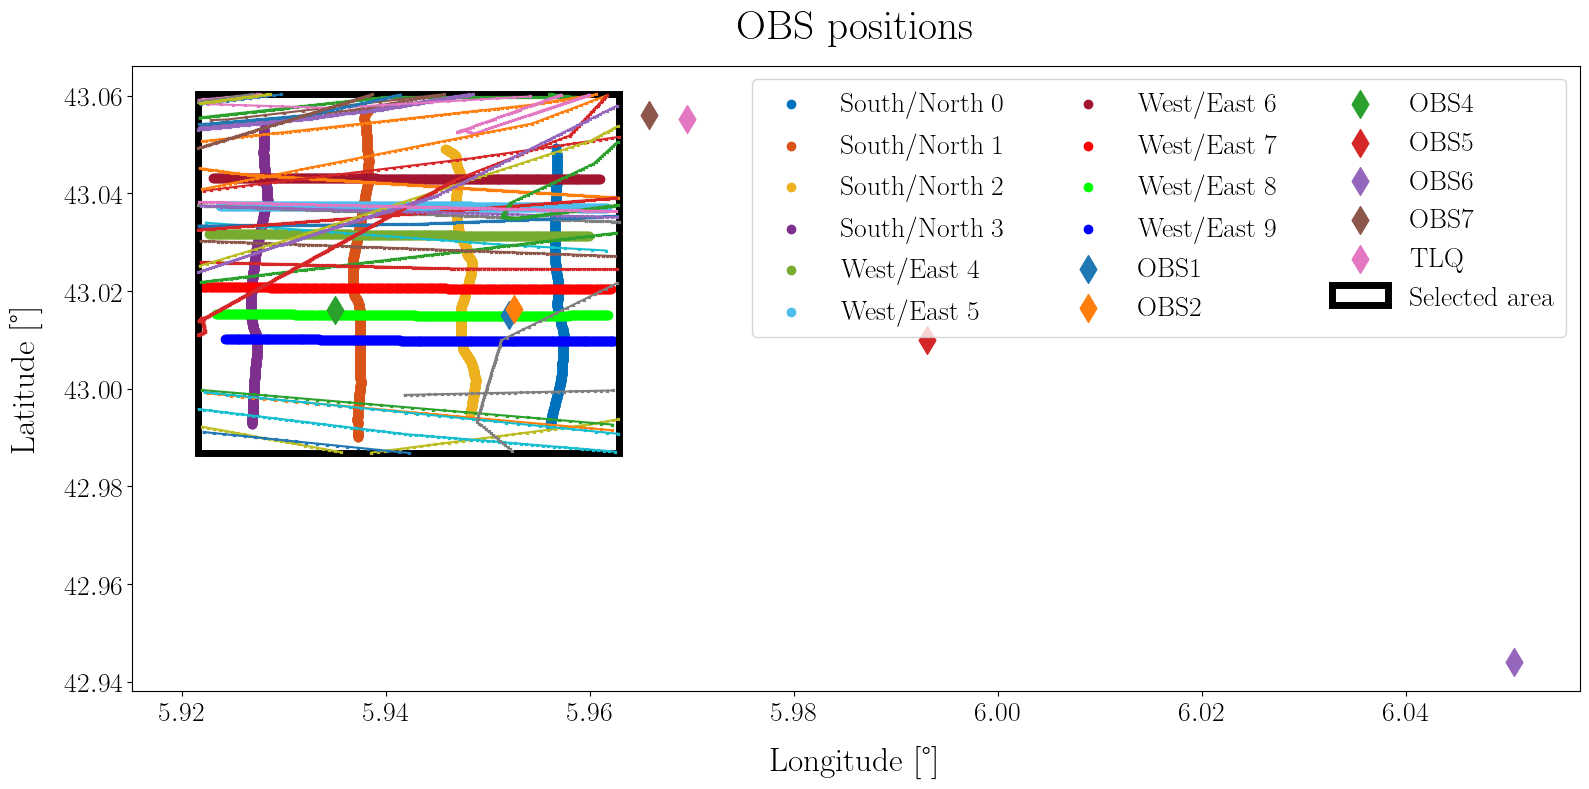

In [37]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event.box_lon_min, portion_event.box_lat_min),
        portion_event.box_lon_max - portion_event.box_lon_min,
        portion_event.box_lat_max - portion_event.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)
ax.legend(ncols=3)

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

# ax.legend()
# legend = ax.get_legend()

# if legend is not None:
#     handles = legend.legend_handles
#     labels = [text.get_text() for text in legend.get_texts()]

#     legend.remove()

#     ax.legend(
#         handles,
#         labels,
#         loc="upper right",
#         fontsize=16,
#         ncols=2,
#     )

In [38]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 39)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 312B 0 1 2 3 4 5 6 7 8 ... 31 32 33 34 35 36 37 38
│   Attributes:
│       box_lon_min:  5.921525852249999
│       box_lon_max:  5.962816177675
│       box_lat_min:  42.986809747449996
│       box_lat_max:  43.060361284900004
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 12)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 96B 2026-02-27T09:04:30 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 96B 5.922 5.922 5.923 ... 5.929 5.93
    │           lat             (datetime) float64 96B 43.06 43.06 43.06 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-27T09:04:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:06:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     1
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 204)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-27T16:13:30 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 2kB 5.963 5.963 5.962 ... 5.922 5.922
    │           lat             (datetime) float64 2kB 43.04 43.04 43.04 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-27T16:13:30
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T16:47:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     6
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 148)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T16:10:40 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 5.956 5.956 5.956 ... 5.922 5.922
    │           lat             (datetime) float64 1kB 43.06 43.06 43.06 ... 43.06 43.06
    │           start_datetime  datetime64[ns] 8B 2026-02-24T16:10:40
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T16:35:10
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     7
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 58)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 464B 2026-02-27T09:33:20 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 464B 5.922 5.923 5.924 ... 5.962 5.963
    │           lat             (datetime) float64 464B 43.04 43.04 43.04 ... 43.05 43.05
    │           start_datetime  datetime64[ns] 8B 2026-02-27T09:33:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:42:50
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     9
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 99)
    │       Coordinates:
    │         

In [39]:
# event_without_intersections_id = [0, 3, 7]
# valid_events_id = [
#     ev_id for ev_id in portion_event.event_id.values if ev_id not in event_without_intersections_id
# ]
# valid_events = [f"event_{ev_id}" for ev_id in valid_events_id]

In [40]:
# # Rebuild datatree with correct event names once unvalid ones have been dropped
# portion_event_filter = xr.DataTree()

# for e_id_new, event_name in enumerate(valid_events):
    
#     path_pos = f"position/{event_name}"
#     new_path_pos = f"position/event_{e_id_new}"
#     old_pos_event = portion_event[path_pos].to_dataset()
#     old_pos_event.attrs["event_id"] = e_id_new
#     portion_event_filter[new_path_pos] = old_pos_event


# portion_event_filter["event_id"] = np.arange(len(valid_events))
# portion_event_filter.attrs = portion_event.attrs

# del portion_event
# portion_event = portion_event_filter.copy()
# del portion_event_filter

In [41]:
# # Plot
# fig, ax = plot_portion_tir_pos(portion_tree=portion)
# ax.add_patch(
#     Rectangle(
#         (portion_event.box_lon_min, portion_event.box_lat_min),
#         portion_event.box_lon_max - portion_event.box_lon_min,
#         portion_event.box_lat_max - portion_event.box_lat_min,
#         fc="none",
#         ec="k",
#         lw=5,
#         label="Selected area",
#     )
# )

# for name, node in portion_event.position.children.items():
#     ds_position_section = node.to_dataset()
#     plt.plot(
#         ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
#     )

# ax.legend()
# legend = ax.get_legend()

# if legend is not None:
#     handles = legend.legend_handles
#     labels = [text.get_text() for text in legend.get_texts()]

#     legend.remove()

#     ax.legend(
#         handles,
#         labels,
#         loc="upper right",
#         fontsize=16,
#         ncols=2,
#     )

In [42]:
# fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# for iobs, o_id in enumerate(ds_pressure.obs_id.values):
#     start = ds_pressure.start_datetime.sel(obs_id=o_id).values
#     stop = start + np.timedelta64(
#         int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{o_id}"] * 1e6), "us"
#     )

#     axs[0].plot([start, stop], [iobs / 10, iobs / 10], label=f"{o_id.upper()}", linewidth=5)
# axs[0].legend()
# axs[0].set_title("Disponibilité des données OBS")

# axs[1].plot(
#     ds_pos_filtered1.src_datetime,
#     np.ones(ds_pos_filtered1.src_datetime.size),
#     color="b",
#     label="Emissions de la source avant émissions sur OBS 6",
#     linewidth=4,
# )

# axs[1].plot(
#     ds_pos_filtered2.src_datetime,
#     np.ones(ds_pos_filtered2.src_datetime.size),
#     color="r",
#     label="Emissions de la source après émissions sur OBS 6",
#     linewidth=4,
# )

# for name, node in portion_event.position.children.items():
#     ds_position_event = node.to_dataset()
#     axs[1].plot(
#         ds_position_event.datetime,
#         np.ones(ds_position_event.datetime.size) + ds_position_event.event_id + 1 ,
#         linewidth=4,
#     )

# axs[1].legend()
# axs[1].set_title("Event AIS et émissions")

# Extraction signaux associés aux navires sélectionnés 

## Extraction et stockage 

In [43]:
event_to_drop = []
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    # NOTE : this section should be useless considering previous filters it is just a extra level of security
    invalid_event = False
    for obs_id in ds_pressure.obs_id.values:
        # Check if any data is available
        start = ds_pressure.start_datetime.sel(obs_id=obs_id).values
        stop = start + np.timedelta64(
            int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{obs_id}"] * 1e6), "us"
        )
        event_stops_before_recording = start >= event_stop
        event_starts_after_recording = stop <= event_start
        no_data = event_stops_before_recording or event_starts_after_recording
        if no_data:
            print(f"OBS '{obs_id}' has no data between {event_start} and {event_stop} (recording spans {start} -> {stop}).")
            invalid_event = True

    if invalid_event:
        # portion_event.drop_nodes()
        print(f"Event {name} dropped")
        event_to_drop.append(name)
        continue

    ds_pressure_event = extract_pressure_section(
        event_start,
        event_stop,
        ds_pressure,
        obs_datetimes=None,
    )
    ds_pressure_event = convert_raw_pressure_to_physical_units(
        ds_pressure=ds_pressure_event
    )

    ds_pressure_event.attrs["event_id"] = ds_position_event.event_id

    # Store in event portion
    path = f"pressure/event_{ds_position_event.event_id}"
    portion_event[path] = ds_pressure_event

In [44]:
portion_event 

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 39)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 312B 0 1 2 3 4 5 6 7 8 ... 31 32 33 34 35 36 37 38
│   Attributes:
│       box_lon_min:  5.921525852249999
│       box_lon_max:  5.962816177675
│       box_lat_min:  42.986809747449996
│       box_lat_max:  43.060361284900004
├── Group: /position
│   ├── Group: /position/event_0
│   │       Dimensions:         (datetime: 12)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 96B 2026-02-27T09:04:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 96B 5.922 5.922 5.923 ... 5.929 5.93
│   │           lat             (datetime) float64 96B 43.06 43.06 43.06 ... 43.06 43.06
│   │           start_datetime  datetime64[ns] 8B 2026-02-27T09:04:30
│   │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:06:20
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 0
│   │           MMSI:                     1
│   ├── Group: /position/event_1
│   │       Dimensions:         (datetime: 204)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-27T16:13:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 2kB 5.963 5.963 5.962 ... 5.922 5.922
│   │           lat             (datetime) float64 2kB 43.04 43.04 43.04 ... 43.05 43.05
│   │           start_datetime  datetime64[ns] 8B 2026-02-27T16:13:30
│   │           stop_datetime   datetime64[ns] 8B 2026-02-27T16:47:20
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 1
│   │           MMSI:                     6
│   ├── Group: /position/event_2
│   │       Dimensions:         (datetime: 148)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T16:10:40 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 1kB 5.956 5.956 5.956 ... 5.922 5.922
│   │           lat             (datetime) float64 1kB 43.06 43.06 43.06 ... 43.06 43.06
│   │           start_datetime  datetime64[ns] 8B 2026-02-24T16:10:40
│   │           stop_datetime   datetime64[ns] 8B 2026-02-24T16:35:10
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 2
│   │           MMSI:                     7
│   ├── Group: /position/event_3
│   │       Dimensions:         (datetime: 58)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 464B 2026-02-27T09:33:20 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 464B 5.922 5.923 5.924 ... 5.962 5.963
│   │           lat             (datetime) float64 464B 43.04 43.04 43.04 ... 43.05 43.05
│   │           start_datetime  datetime64[ns] 8B 2026-02-27T09:33:20
│   │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:42:50
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 3
│   │           MMSI:                     9
│   ├── Group: /position/event_4
│   │       Dimensions:         (datetime: 99)
│   │       Coordinates:
│   │         

In [45]:
event_to_drop = []
for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    event_start = ds_position_event.start_datetime.values
    event_stop = ds_position_event.stop_datetime.values

    # NOTE : this section should be useless considering previous filters it is just a extra level of security
    invalid_event = False
    for obs_id in ds_pressure.obs_id.values:
        # Check if any data is available
        start = ds_pressure.start_datetime.sel(obs_id=obs_id).values
        stop = start + np.timedelta64(
            int(1 / ds_pressure.fs * ds_pressure.sizes[f"time_{obs_id}"] * 1e6), "us"
        )
        event_stops_before_recording = start >= event_stop
        event_starts_after_recording = stop <= event_start
        no_data = event_stops_before_recording or event_starts_after_recording
        if no_data:
            print(f"OBS '{obs_id}' has no data between {event_start} and {event_stop} (recording spans {start} -> {stop}).")
            invalid_event = True

    if invalid_event:
        # portion_event.drop_nodes()
        print(f"Event {name} dropped")
        event_to_drop.append(name)
        continue

    ds_pressure_event = extract_pressure_section(
        event_start,
        event_stop,
        ds_pressure,
        obs_datetimes=None,
    )
    ds_pressure_event = convert_raw_pressure_to_physical_units(
        ds_pressure=ds_pressure_event
    )

    ds_pressure_event.attrs["event_id"] = ds_position_event.event_id

    # Store in event portion
    path = f"pressure/event_{ds_position_event.event_id}"
    portion_event[path] = ds_pressure_event

## Visualisation des signaux 

Pour le tracer des signaux des event sélectionnés voir le notebook d'illustration dédié. 

In [46]:
# # Plot
# single_fig = False
# for name, node in portion_event.pressure.children.items():
#     ds_pressure_section = node.to_dataset()
#     fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
#     fig.suptitle(f"Event {ds_pressure_section.event_id}")
#     plt.show()

## Spectrogrames 


In [47]:
# # Plot
# # root_img_spectro = r""
# for name, node in portion_event.pressure.children.items():
#     if name != "event_3":
#         continue
#     ds_pressure_section = node.to_dataset()
#     try:
#         fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**10, noverlap=2**9, cmap="magma")
#     except:
#         print(f"Data with different length event : {name}")
#     fig.suptitle(f"Event {ds_pressure_section.event_id}")
#     # plt.show()

In [48]:
event_days = np.concat(
    [
        pd.DatetimeIndex(node.datetime).day
        for name, node in portion_event.position.children.items()
    ]
)
event_days, unique_idx = np.unique(event_days, return_index=True)
event_days

event_months = np.concat(
    [
        pd.DatetimeIndex(node.datetime).month
        for name, node in portion_event.position.children.items()
    ]
)
event_months = event_months[unique_idx]
event_months
event_years = np.concat(
    [
        pd.DatetimeIndex(node.datetime).year
        for name, node in portion_event.position.children.items()
    ]
)
event_years = event_years[unique_idx]

dt_bounds = np.asarray(
    [
        np.datetime64(
            datetime(year=event_years[i], month=event_months[i], day=event_days[i])
        )
        for i in range(event_days.size)
    ]
)
dt_bounds = np.sort(dt_bounds)
dt_bounds

array(['2026-02-24T00:00:00.000000', '2026-02-25T00:00:00.000000',
       '2026-02-27T00:00:00.000000', '2026-02-28T00:00:00.000000',
       '2026-03-01T00:00:00.000000'], dtype='datetime64[us]')

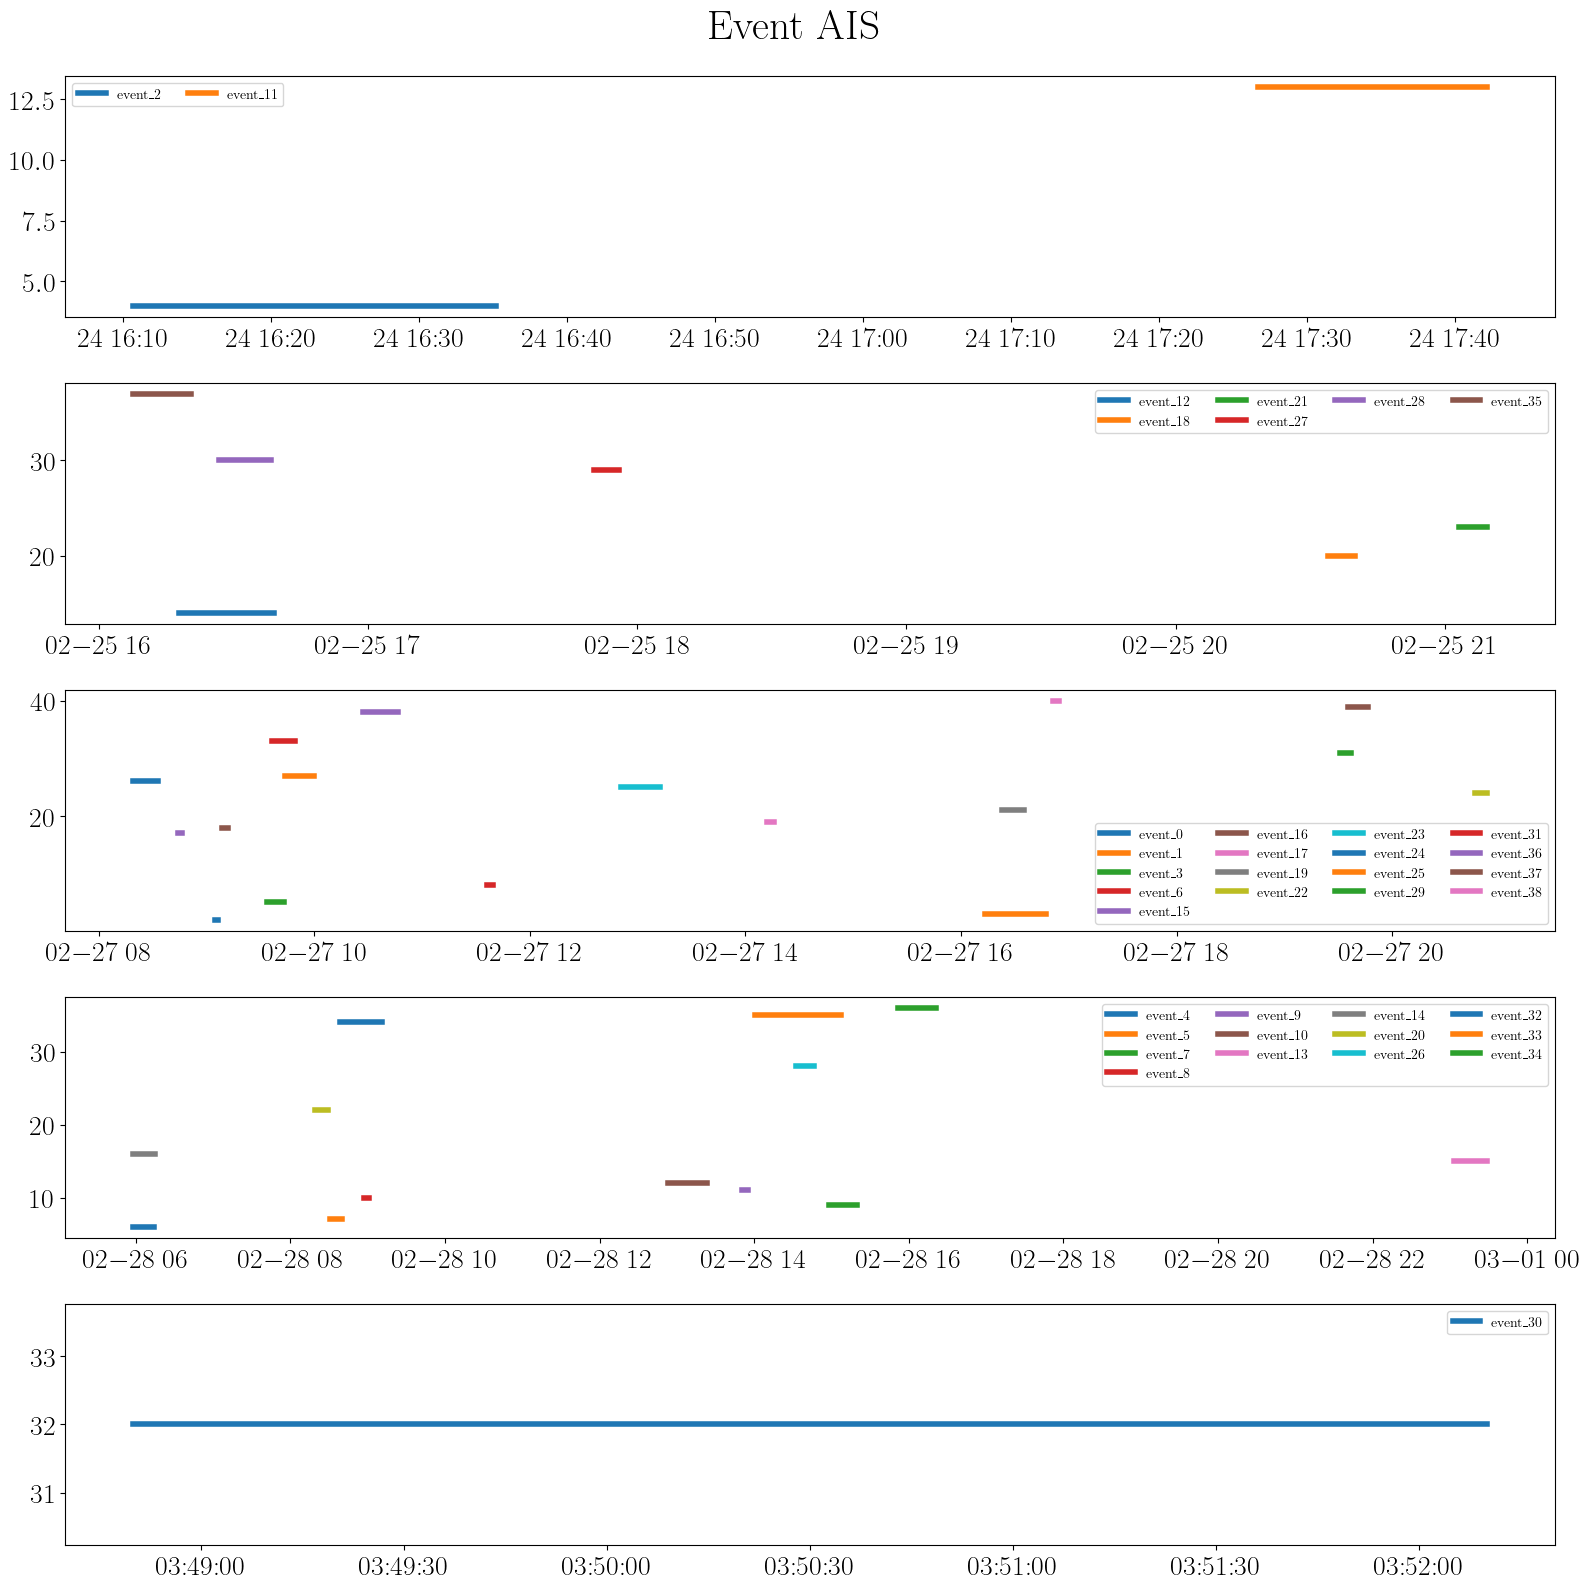

In [49]:
fig, axs = plt.subplots(dt_bounds.size, 1, figsize=(16, 16), sharex=False)

for name, node in portion_event.position.children.items():
    ds_position_event = node.to_dataset()

    # Choose ax
    dt = ds_position_event.datetime
    if dt.min() <= dt_bounds[1]:
        ax = axs[0]
    elif dt.min() >= dt_bounds[1] and  dt.max() <= dt_bounds[2]:
        ax = axs[1]
    elif dt.min() >= dt_bounds[2] and  dt.max() <= dt_bounds[3]:
        ax = axs[2]
    elif dt.min() >= dt_bounds[3] and  dt.max() <= dt_bounds[4]:
        ax = axs[3]
    elif dt.min() >= dt_bounds[4]:
        ax = axs[4]

    ax.plot(
        ds_position_event.datetime,
        np.ones(ds_position_event.datetime.size) + ds_position_event.event_id + 1 ,
        linewidth=4,
        label=name
    )

    # ax.legend(fontsize=10)

fig.suptitle("Event AIS")
for ax in axs.flatten():
    ax.legend(fontsize=10, ncols=4)

# fpath = os.path.join(root_img_selection, "event_ais_temporal_coverage.png")
# fig.savefig(fpath)

# Sauvergarde de la portion event 

In [50]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 39)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 312B 0 1 2 3 4 5 6 7 8 ... 31 32 33 34 35 36 37 38
│   Attributes:
│       box_lon_min:  5.921525852249999
│       box_lon_max:  5.962816177675
│       box_lat_min:  42.986809747449996
│       box_lat_max:  43.060361284900004
├── Group: /position
│   ├── Group: /position/event_0
│   │       Dimensions:         (datetime: 12)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 96B 2026-02-27T09:04:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 96B 5.922 5.922 5.923 ... 5.929 5.93
│   │           lat             (datetime) float64 96B 43.06 43.06 43.06 ... 43.06 43.06
│   │           start_datetime  datetime64[ns] 8B 2026-02-27T09:04:30
│   │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:06:20
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 0
│   │           MMSI:                     1
│   ├── Group: /position/event_1
│   │       Dimensions:         (datetime: 204)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 2kB 2026-02-27T16:13:30 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 2kB 5.963 5.963 5.962 ... 5.922 5.922
│   │           lat             (datetime) float64 2kB 43.04 43.04 43.04 ... 43.05 43.05
│   │           start_datetime  datetime64[ns] 8B 2026-02-27T16:13:30
│   │           stop_datetime   datetime64[ns] 8B 2026-02-27T16:47:20
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 1
│   │           MMSI:                     6
│   ├── Group: /position/event_2
│   │       Dimensions:         (datetime: 148)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-24T16:10:40 ... 202...
│   │       Data variables:
│   │           lon             (datetime) float64 1kB 5.956 5.956 5.956 ... 5.922 5.922
│   │           lat             (datetime) float64 1kB 43.06 43.06 43.06 ... 43.06 43.06
│   │           start_datetime  datetime64[ns] 8B 2026-02-24T16:10:40
│   │           stop_datetime   datetime64[ns] 8B 2026-02-24T16:35:10
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 2
│   │           MMSI:                     7
│   ├── Group: /position/event_3
│   │       Dimensions:         (datetime: 58)
│   │       Coordinates:
│   │         * datetime        (datetime) datetime64[ns] 464B 2026-02-27T09:33:20 ... 20...
│   │       Data variables:
│   │           lon             (datetime) float64 464B 5.922 5.923 5.924 ... 5.962 5.963
│   │           lat             (datetime) float64 464B 43.04 43.04 43.04 ... 43.05 43.05
│   │           start_datetime  datetime64[ns] 8B 2026-02-27T09:33:20
│   │           stop_datetime   datetime64[ns] 8B 2026-02-27T09:42:50
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           event_id:                 3
│   │           MMSI:                     9
│   ├── Group: /position/event_4
│   │       Dimensions:         (datetime: 99)
│   │       Coordinates:
│   │         

In [51]:
# Save as netcdf
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event.attrs["portion_filepath"] = fpath
portion_event.to_netcdf(fpath)

In [52]:
# portion_event_ = portion_event.match("*/event_9")

# # Save as netcdf
# fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
# portion_event_.attrs["portion_filepath"] = fpath
# portion_event_.to_netcdf(fpath)

# portion_event_

# Sélection de quelques trajectoires favorables

On sélectionne les trajectoires via l'analyse des premiers résultats sur la portion event complète (34 traj)

In [ ]:
valid_events_id = [
    3, 8, 10, 16, 18, 19, 25, 31, 34
]
valid_events = [f"event_{ev_id}" for ev_id in valid_events_id]

In [ ]:
# Rebuild datatree with correct event names once unvalid ones have been dropped
portion_event_filter = xr.DataTree()

for e_id_new, event_name in enumerate(valid_events):

    e_id_new = int(event_name.split("_")[-1])
    path_pos = f"position/{event_name}"
    new_path_pos = f"position/event_{e_id_new}"
    old_pos_event = portion_event[path_pos].to_dataset()
    old_pos_event.attrs["event_id"] = e_id_new
    portion_event_filter[new_path_pos] = old_pos_event

    path_pos = f"pressure/{event_name}"
    new_path_pos = f"pressure/event_{e_id_new}"
    old_pos_event = portion_event[path_pos].to_dataset()
    old_pos_event.attrs["event_id"] = e_id_new
    portion_event_filter[new_path_pos] = old_pos_event

portion_event_filter["event_id"] = np.arange(len(valid_events))
portion_event_filter.attrs = portion_event.attrs

# del portion_event
# portion_event = portion_event_filter.copy()
# del portion_event_filter

In [ ]:
# Plot
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (portion_event_filter.box_lon_min, portion_event_filter.box_lat_min),
        portion_event_filter.box_lon_max - portion_event_filter.box_lon_min,
        portion_event_filter.box_lat_max - portion_event_filter.box_lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for name, node in portion_event_filter.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.lon, ds_position_section.lat, "-x", markersize=2, label=f"Event {ds_position_section.event_id}"
    )

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

In [ ]:
# Save as netcdf
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event_ais.nc"
portion_event_filter.attrs["portion_filepath"] = fpath
portion_event_filter.to_netcdf(fpath)